# COMP4153 Natural Language Processing
# Lab 3 — Neural Networks for Text Classification

**Version:** Solution  
**Duration:** approximately 2 hours  
**Environment:** Google Colab or local Jupyter Notebook  
**Mode:** self-guided — read the explanations and run cells in order.

This lab introduces a **small neural text classifier** using word embeddings, mean pooling and a multilayer perceptron (MLP).

- **Part A — Guided IMDB example:** see how every stage of the pipeline works.
- **Part B — Twitter practice:** reuse the same code on another dataset, then complete **four focused tasks** (training, plots, evaluation and error analysis).

```text
text → tokenise → training vocabulary → padded token IDs
→ embeddings → masked mean pooling → MLP → sentiment prediction
                   ↓
       loss → gradients → optimiser update
```

## Learning objectives

By the end of the lab, you should be able to:

- distinguish training, development and test splits;
- convert text to tokens, vocabulary IDs and fixed-length tensors;
- describe the purpose of `Dataset` and `DataLoader`;
- trace tensor shapes through trainable embeddings, mean pooling and an MLP;
- interpret cross-entropy, backpropagation and an optimiser update;
- select the best **completed** epoch using development loss without stopping training early;
- read learning curves, accuracy, macro F1 and confusion matrices;
- inspect misclassified examples and explain why mean pooling loses word order.

## Suggested timing

| Part | Approx. time |
|---|---:|
| Setup | 5 min |
| Part A — Guided IMDB classifier | 70 min |
| Part B — Guided Twitter preparation and four short tasks | 45 min |

# 0. Setup

This notebook uses two local CSV files:

- `imdb_reviews_10000_fixed_split.csv`
- `twitter_sentiment_fixed_split.csv`

The IMDB file is a **fixed subset of 10,000 reviews sampled from the complete 50,000-review IMDB Movie Review Dataset**. The complete dataset is available from Kaggle:

[Complete 50,000-review IMDB Movie Review Dataset](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews)

The supplied 10,000-review subset is balanced:

```text
5,000 positive reviews
5,000 negative reviews
```

and already contains a fixed split:

```text
8,000 training reviews
1,000 development reviews
1,000 test reviews
```

`twitter_sentiment_fixed_split.csv` is used for Part B of this lab. It also already contains fixed training, development, and test splits.

Do not reshuffle or recreate either supplied split. Keeping the split fixed makes the experiments reproducible.

## 0.1 Import the libraries

The main libraries are:

- **NumPy** and **pandas** for data handling;
- **NLTK tokenisers** for text preprocessing;
- **PyTorch** for neural-network modelling;
- **scikit-learn** for evaluation metrics;
- **Matplotlib** for learning curves and diagnostic plots.

In [ ]:
from pathlib import Path
from collections import Counter
import copy
import os
import random
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.tokenize import TreebankWordTokenizer, TweetTokenizer

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

## 0.2 Detect the environment and locate the Lab 3 folder

For Google Colab, the notebook looks in `My Drive/COMP4153/Lab3`.

For local Jupyter, keep the notebook and the two CSV files in the same folder and start Jupyter from that folder.

If your Google Drive folder is different, change `COLAB_LAB_DIR`.

In [ ]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    COLAB_LAB_DIR = Path("/content/drive/MyDrive/COMP4153/Lab3")
    LAB_DIR = COLAB_LAB_DIR
    print("Environment: Google Colab")
else:
    LAB_DIR = Path.cwd()
    print("Environment: local Jupyter Notebook")

if not LAB_DIR.exists():
    raise FileNotFoundError(f"Lab folder not found: {LAB_DIR}")

os.chdir(LAB_DIR)
print("Working directory:", Path.cwd())

Mounted at /content/drive
Environment: Google Colab
Working directory: /content/drive/MyDrive/COMP4153/Lab3


## 0.3 Check the required data files

The notebook uses local CSV files only. It does not download datasets at runtime.

In [ ]:
required_files = [
    "imdb_reviews_10000_fixed_split.csv",
    "twitter_sentiment_fixed_split.csv",
]

for filename in required_files:
    print(f"{filename:40s}", Path(filename).exists())

missing = [f for f in required_files if not Path(f).exists()]

if missing:
    raise FileNotFoundError(
        "Missing required file(s): " + ", ".join(missing)
    )

imdb_reviews_10000_fixed_split.csv       True
twitter_sentiment_fixed_split.csv        True


## 0.4 Reproducibility and PyTorch device

A fixed random seed makes repeated runs more reproducible. If a GPU is available, PyTorch uses it automatically.

In [ ]:
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.11.0+cu130
Device: cuda


---
# Part A — Guided IMDB sentiment classification

**Goal:** train a small neural network to decide whether a movie review is positive or negative.

```text
Review → tokens → word IDs → trainable word embeddings
       → average the real word vectors → MLP → two sentiment scores
```

This is a **guided example**: run each cell and observe the inputs and outputs. You will reuse the same functions for Twitter sentiment classification in Part B.

The most important ideas are **embeddings, a hidden layer with ReLU, cross-entropy, backpropagation, and evaluating on unseen data**. The data-preparation helpers are provided so that you can focus on these concepts.

## A1. Load the data and use the supplied splits

The CSV contains `text` (review), `label` (`negative` / `positive`) and `split` (`train` / `dev` / `test`).

We use the splits **exactly as provided**:

- **Train:** update the neural-network weights.
- **Development:** select the checkpoint with the lowest loss after a completed epoch.
- **Test:** measure performance once after training.

The notebook does not create a new random split.

In [ ]:
imdb_df = pd.read_csv("imdb_reviews_10000_fixed_split.csv")

# Show some examples and verify the provided splits.
display(imdb_df.head(3))
display(pd.crosstab(imdb_df["split"], imdb_df["label"]))

imdb_train_df = imdb_df[imdb_df["split"] == "train"].reset_index(drop=True)
imdb_dev_df = imdb_df[imdb_df["split"] == "dev"].reset_index(drop=True)
imdb_test_df = imdb_df[imdb_df["split"] == "test"].reset_index(drop=True)

print("Train / development / test:", len(imdb_train_df), len(imdb_dev_df), len(imdb_test_df))

,text,label,split
0,This may not be the very worst movie Peter Sel...,negative,train
1,Yet another version of mother of all gangster ...,negative,train
2,"I'm a fan of Judy Garland, Vincente Minnelli, ...",negative,train


label,negative,positive
split,,
dev,500,500
test,500,500
train,4000,4000


Train / development / test: 8000 1000 1000


## A2. Turn words into vocabulary IDs

The network uses **integers rather than text strings**. We lowercase and tokenise each review with NLTK, then construct a vocabulary from **training reviews only**.

Two special IDs are reserved:

```text
<PAD> = 0   fill unused positions in shorter reviews
<UNK> = 1   replace any word not found in the training vocabulary
```

Try the example tokeniser output, then check the vocabulary size and common words. Word IDs are only lookup addresses; they are not numerical word meanings.

In [ ]:
treebank_tokenizer = TreebankWordTokenizer()

def tokenize_imdb_nn(text):
    tokens = treebank_tokenizer.tokenize(
        str(text).lower()
    )

    return [
        token
        for token in tokens
        if len(token) > 1
        and any(ch.isalpha() for ch in token)
    ]

print(
    tokenize_imdb_nn(
        "This movie was not very good, but the ending was excellent!"
    )
)
PAD_TOKEN = "<PAD>"
UNK_TOKEN = "<UNK>"

PAD_IDX = 0
UNK_IDX = 1

def build_vocab(texts, tokenizer_fn, max_vocab=10000, min_freq=2):
    counter = Counter()

    for text in texts:
        counter.update(
            tokenizer_fn(text)
        )

    vocab = {
        PAD_TOKEN: PAD_IDX,
        UNK_TOKEN: UNK_IDX,
    }

    for token, count in counter.most_common(max_vocab):
        if (
            count >= min_freq
            and token not in vocab
        ):
            vocab[token] = len(vocab)

    return vocab, counter

imdb_vocab, imdb_counter = build_vocab(
    imdb_train_df["text"],
    tokenize_imdb_nn,
    max_vocab=10000,
    min_freq=2,
)

print("IMDB vocabulary size:", len(imdb_vocab))
print("20 most frequent training tokens:")
print(imdb_counter.most_common(20))

['this', 'movie', 'was', 'not', 'very', 'good', 'but', 'the', 'ending', 'was', 'excellent']
IMDB vocabulary size: 10002
20 most frequent training tokens:
[('the', 105552), ('and', 51468), ('of', 45746), ('to', 42106), ('is', 34403), ('in', 29253), ('it', 28514), ('this', 23679), ('that', 22605), ("'s", 19660), ('was', 15771), ('as', 14646), ('for', 13931), ('with', 13891), ('but', 13214), ('movie', 12042), ('film', 10945), ('you', 10920), ("n't", 10587), ('on', 10511)]


## A3. Encode reviews and create PyTorch datasets

For every review, we:

```text
text → tokens → word IDs → first 300 IDs → add <PAD> IDs if needed
```

All reviews are represented by `IMDB_MAX_LEN = 300` positions. For example, with a toy maximum length of 5:

```text
"great movie" → [ID(great), ID(movie), 0, 0, 0]
```

The helper `make_text_dataset()` converts the complete DataFrame into two tensors:

```text
input_ids  [number of reviews, 300]
labels     [number of reviews]
```

We use the built-in PyTorch **`TensorDataset`**, so there is no need to write a custom dataset class. The function accepts a different text column and tokenizer, allowing it to be reused for tweets in Part B.

In [ ]:
LABEL_TO_ID = {"negative": 0, "positive": 1}
ID_TO_LABEL = {0: "negative", 1: "positive"}
IMDB_MAX_LEN = 300

# Keep the token order, truncate long texts, and add PAD IDs to short texts.
def encode_text(text, tokenizer_fn, vocab, max_len):
    ids = [vocab.get(token, UNK_IDX) for token in tokenizer_fn(text)]
    ids = ids[:max_len]
    return ids + [PAD_IDX] * (max_len - len(ids))

# The built-in TensorDataset stores (input_ids, label) pairs.
def make_text_dataset(dataframe, tokenizer_fn, vocab, max_len, text_column="text"):
    input_ids = torch.tensor(
        [encode_text(text, tokenizer_fn, vocab, max_len) for text in dataframe[text_column]],
        dtype=torch.long,
    )
    labels = torch.tensor(
        [LABEL_TO_ID[label] for label in dataframe["label"]],
        dtype=torch.long,
    )
    return TensorDataset(input_ids, labels)

imdb_train_dataset = make_text_dataset(
    imdb_train_df,
    tokenize_imdb_nn,
    imdb_vocab,
    IMDB_MAX_LEN,
)
imdb_dev_dataset = make_text_dataset(
    imdb_dev_df,
    tokenize_imdb_nn,
    imdb_vocab,
    IMDB_MAX_LEN,
)
imdb_test_dataset = make_text_dataset(
    imdb_test_df,
    tokenize_imdb_nn,
    imdb_vocab,
    IMDB_MAX_LEN,
)

print("Training inputs:", imdb_train_dataset.tensors[0].shape)
print("Training labels:", imdb_train_dataset.tensors[1].shape)
print("One example label:", imdb_train_dataset[0][1].item())

Training inputs: torch.Size([8000, 300])
Training labels: torch.Size([8000])
One example label: 0


## A4. Group examples into mini-batches

A `DataLoader` groups individual examples into mini-batches. With a batch size of 64:

```text
input_ids: [64, 300]
labels:    [64]
```

We shuffle training examples, but not development/test examples. The helper below is reused for both datasets; the desired batch size is specified when we train.

In [ ]:
def make_loaders(train_dataset, dev_dataset, test_dataset, train_batch_size, eval_batch_size=128, seed=SEED):
    generator = torch.Generator().manual_seed(
        seed
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=train_batch_size,
        shuffle=True,
        generator=generator,
    )

    dev_loader = DataLoader(
        dev_dataset,
        batch_size=eval_batch_size,
        shuffle=False,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=eval_batch_size,
        shuffle=False,
    )

    return (
        train_loader,
        dev_loader,
        test_loader,
    )

## A5. Define the embedding + MLP classifier

The following **single small network** is the main model in this lab:

```text
input_ids       [B, 300]
Embedding       [B, 300, 64]     ← one learnable vector per word ID
Masked average  [B, 64]          ← ignore <PAD> when averaging
Linear + ReLU   [B, 64]          ← learned nonlinear hidden layer
Dropout         [B, 64]          ← regularisation during training
Linear          [B, 2]           ← negative/positive scores (logits)
```

**Why average?** The input review can be long or short, but the hidden layer needs one fixed-size vector. We average the **real** word embeddings only. `<PAD>` positions must not lower the average.

**Why ReLU?** Without a nonlinear activation, stacked linear layers are equivalent to one linear transformation.

**Why logits?** The model outputs two raw scores, not probabilities. `CrossEntropyLoss` takes these scores directly.

In [ ]:
class MeanEmbeddingMLP(nn.Module):
    def __init__(self, vocab_size, pad_idx=PAD_IDX, embedding_dim=64, hidden_dim=64, dropout=0.3):
        super().__init__()
        self.pad_idx = pad_idx
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.hidden = nn.Linear(embedding_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(hidden_dim, 2)

    def mean_pool(self, input_ids):
        # [B, T] -> [B, T, d]: look up a learnable word vector for each ID.
        embedded = self.embedding(input_ids)

        # [B, T, 1]: 1 for real words, 0 for <PAD>.
        mask = (input_ids != self.pad_idx).unsqueeze(-1)

        # Sum only real-word embeddings, then divide by the number of real words.
        # clamp(min=1) avoids division by zero if a text is empty.
        return (embedded * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)

    def forward(self, input_ids):
        # One average embedding vector per review: [B, d].
        review_vector = self.mean_pool(input_ids)
        hidden = self.relu(self.hidden(review_vector))
        hidden = self.dropout(hidden)
        return self.output(hidden)  # [B, 2] raw sentiment scores

## A6. How training and evaluation work

**Prediction:** the model returns two raw scores `[B, 2]`. Negative is class `0`; positive is class `1`. We use `CrossEntropyLoss` without applying softmax first.

For each training mini-batch, the core PyTorch steps are:

```python
optimiser.zero_grad()            # clear previous gradients
logits = model(input_ids)        # forward pass
loss = loss_fn(logits, labels)    # compare to correct labels
loss.backward()                  # backpropagation
optimiser.step()                 # update weights
```

The provided helpers handle batching and record training/development metrics. For evaluation, they use `model.eval()` and `torch.no_grad()` so that no parameters are updated.

Training **always completes every configured epoch**. We save the model state with the lowest completed **development loss** and restore it afterward. The test split is not used for checkpoint selection.

Read the five training operations above carefully; the longer bookkeeping code is provided for you.

In [ ]:
def evaluate_model(model, data_loader, loss_fn, device):
    model.eval()

    total_loss = 0.0
    total_examples = 0
    correct = 0

    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for input_ids, labels in data_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            logits = model(input_ids)
            loss = loss_fn(
                logits,
                labels,
            )

            predictions = logits.argmax(
                dim=1
            )

            batch_size = labels.size(0)

            total_loss += (
                loss.item() * batch_size
            )

            total_examples += batch_size

            correct += (
                predictions == labels
            ).sum().item()

            all_predictions.extend(
                predictions.cpu().tolist()
            )

            all_targets.extend(
                labels.cpu().tolist()
            )

    average_loss = (
        total_loss / total_examples
    )

    accuracy = (
        correct / total_examples
    )

    return (
        average_loss,
        accuracy,
        all_predictions,
        all_targets,
    )

In [ ]:
def train_model(model, train_loader, dev_loader, loss_fn, optimiser, device, epochs=10):
    # Store one row of statistics per completed epoch.
    history = []

    # Development data never updates model parameters.
    # It is used only to remember the best completed epoch.
    best_dev_loss = float("inf")
    best_dev_accuracy = -1.0
    best_epoch = None
    best_state = None

    for epoch in range(1, epochs + 1):
        model.train()

        total_train_loss = 0.0
        total_train_examples = 0

        for input_ids, labels in train_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)

            # Clear gradients left from the previous mini-batch.
            optimiser.zero_grad()

            # Forward pass: [B, T] -> [B, 2].
            logits = model(input_ids)
            loss = loss_fn(logits, labels)

            # Compute gradients for embeddings and MLP parameters.
            loss.backward()

            # Update parameters with Adam.
            optimiser.step()

            # Convert batch-mean loss into a sample-weighted sum.
            batch_size = labels.size(0)
            total_train_loss += loss.item() * batch_size
            total_train_examples += batch_size

        train_loss = total_train_loss / total_train_examples

        # evaluate_model() uses eval mode and no_grad internally.
        dev_loss, dev_accuracy, _, _ = evaluate_model(
            model,
            dev_loader,
            loss_fn,
            device,
        )

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "dev_loss": dev_loss,
            "dev_accuracy": dev_accuracy,
        })

        print(
            f"Epoch {epoch:02d} | "
            f"train loss {train_loss:.4f} | "
            f"dev loss {dev_loss:.4f} | "
            f"dev accuracy {dev_accuracy:.3f}"
        )

        # Save the completed epoch if development loss improves.
        # Training still continues through every requested epoch.
        if dev_loss < best_dev_loss:
            best_dev_loss = dev_loss
            best_dev_accuracy = dev_accuracy
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())

    # Restore the checkpoint selected using development loss.
    model.load_state_dict(best_state)

    print(
        f"\nRestored epoch {best_epoch} | "
        f"best dev loss {best_dev_loss:.4f} | "
        f"dev accuracy {best_dev_accuracy:.3f}"
    )

    return pd.DataFrame(history), best_dev_loss, best_dev_accuracy, best_epoch

## A7. Train the IMDB model

The settings are unchanged from the original lab:

```text
embedding dimension = 64    hidden dimension = 64
dropout = 0.3               batch size = 64
learning rate = 0.001      weight decay = 0.00001
epochs = 10
```

Run the next cell to create the DataLoaders, initialise the model, and train. The helper prints the training loss, development loss and development accuracy after each epoch. A CPU-only computer can run it, although training may take longer.

In [ ]:
EMBEDDING_DIM = 64
HIDDEN_DIM = 64
DROPOUT = 0.3
BATCH_SIZE = 64
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
EPOCHS = 10

imdb_train_loader, imdb_dev_loader, imdb_test_loader = make_loaders(
    imdb_train_dataset,
    imdb_dev_dataset,
    imdb_test_dataset,
    train_batch_size=BATCH_SIZE,
)

set_seed()

imdb_model = MeanEmbeddingMLP(
    vocab_size=len(imdb_vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT,
).to(device)

imdb_loss_fn = nn.CrossEntropyLoss()

imdb_optimiser = torch.optim.Adam(
    imdb_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

imdb_history, imdb_best_dev_loss, imdb_best_dev_accuracy, imdb_best_epoch = train_model(
    imdb_model,
    imdb_train_loader,
    imdb_dev_loader,
    imdb_loss_fn,
    imdb_optimiser,
    device,
    epochs=EPOCHS,
)

Epoch 01 | train loss 0.6782 | dev loss 0.6440 | dev accuracy 0.670
Epoch 02 | train loss 0.5796 | dev loss 0.5308 | dev accuracy 0.733
Epoch 03 | train loss 0.4538 | dev loss 0.4594 | dev accuracy 0.784
Epoch 04 | train loss 0.3726 | dev loss 0.4265 | dev accuracy 0.795
Epoch 05 | train loss 0.3119 | dev loss 0.4039 | dev accuracy 0.813
Epoch 06 | train loss 0.2691 | dev loss 0.3909 | dev accuracy 0.816
Epoch 07 | train loss 0.2290 | dev loss 0.3952 | dev accuracy 0.825
Epoch 08 | train loss 0.1915 | dev loss 0.3993 | dev accuracy 0.828
Epoch 09 | train loss 0.1618 | dev loss 0.4069 | dev accuracy 0.841
Epoch 10 | train loss 0.1331 | dev loss 0.4245 | dev accuracy 0.838

Restored epoch 6 | best dev loss 0.3909 | dev accuracy 0.816


### Examine the learning curves

The first figure compares **training loss** with **development loss**. The second shows **development accuracy**. If training loss falls while development loss rises, the model may be overfitting.

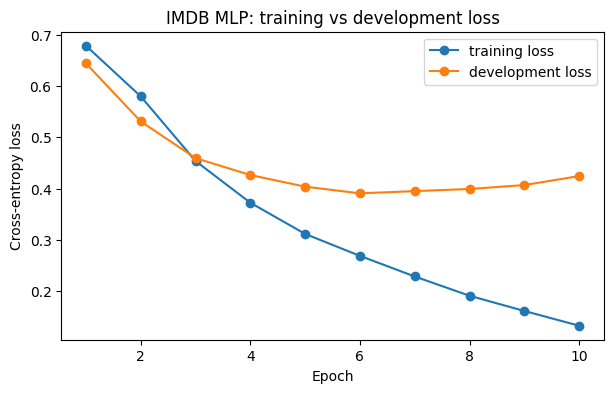

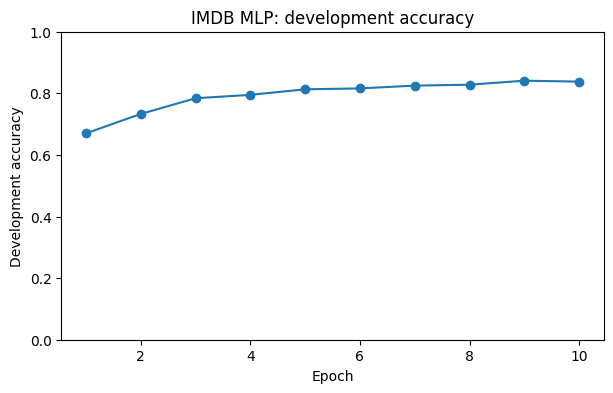

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    imdb_history["epoch"],
    imdb_history["train_loss"],
    marker="o",
    label="training loss",
)

ax.plot(
    imdb_history["epoch"],
    imdb_history["dev_loss"],
    marker="o",
    label="development loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title(
    "IMDB MLP: training vs development loss"
)
ax.legend()
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    imdb_history["epoch"],
    imdb_history["dev_accuracy"],
    marker="o",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Development accuracy")
ax.set_ylim(0, 1)
ax.set_title(
    "IMDB MLP: development accuracy"
)
plt.show()

## A8. Evaluate the trained model on the test set

After all epochs finish, `train_model()` restores the lowest-development-loss checkpoint. We now evaluate the untouched test split:

- **Accuracy:** proportion of correct predictions.
- **Macro F1:** average F1 across negative and positive classes.
- **Confusion matrix:** number of correct and incorrect predictions for each class.

Do not tune the model using the test results.

Test loss:     0.3399
Test accuracy: 0.854
Macro F1:      0.854


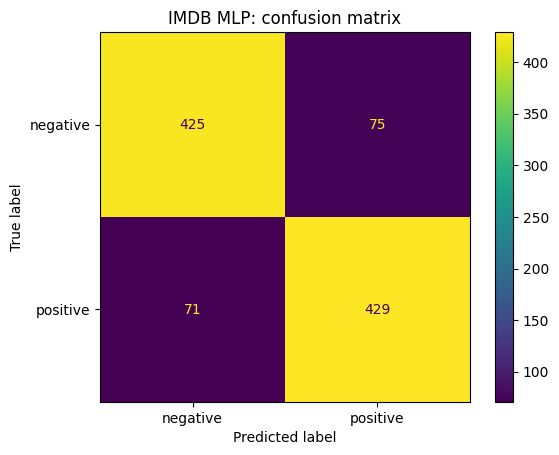

In [ ]:
imdb_test_loss, imdb_test_accuracy, imdb_test_predictions, imdb_test_targets = evaluate_model(
    imdb_model,
    imdb_test_loader,
    imdb_loss_fn,
    device,
)

imdb_test_f1 = f1_score(
    imdb_test_targets,
    imdb_test_predictions,
    average="macro",
)

print(f"Test loss:     {imdb_test_loss:.4f}")
print(f"Test accuracy: {imdb_test_accuracy:.3f}")
print(f"Macro F1:      {imdb_test_f1:.3f}")
imdb_cm = confusion_matrix(
    imdb_test_targets,
    imdb_test_predictions,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=imdb_cm,
    display_labels=[
        "negative",
        "positive",
    ],
)

disp.plot()
plt.title(
    "IMDB MLP: confusion matrix"
)
plt.show()

## A9. Inspect a few mistakes

Metrics tell us **how often** the model makes errors. Looking at actual reviews can suggest **why**: mixed sentiment, negation, irony or long texts can be hard for a bag-of-embeddings model.

The next cell displays a few incorrect predictions. This also provides an example for **Task B4**.

In [ ]:
imdb_results = (
    imdb_test_df
    .reset_index(drop=True)
    .copy()
)

imdb_results["predicted_label"] = [
    ID_TO_LABEL[prediction]
    for prediction in imdb_test_predictions
]

imdb_errors = imdb_results[
    imdb_results["label"]
    != imdb_results["predicted_label"]
].copy()

imdb_errors["text_preview"] = (
    imdb_errors["text"]
    .str.replace(
        "\n",
        " ",
        regex=False,
    )
    .str.slice(0, 300)
)

display(
    imdb_errors[
        [
            "text_preview",
            "label",
            "predicted_label",
        ]
    ].head(5)
)

,text_preview,label,predicted_label
2,"One of the most macabre, depressing, yet eye-o...",positive,negative
21,The villian in this movie is one mean sob and ...,positive,negative
33,Don't get me wrong. I've got a considerable so...,negative,positive
37,If this movie were in production today it woul...,negative,positive
39,City girl Meg Tilly receives a horrifying phon...,negative,positive


---
# Part B — Apply the same model to Twitter sentiment

Part A has already supplied the reusable building blocks:

```text
build_vocab()       → build a vocabulary from training text
make_text_dataset() → create built-in TensorDataset pairs
make_loaders()      → create training/dev/test mini-batches
MeanEmbeddingMLP    → embeddings + mean pooling + MLP
train_model()       → training and best-development checkpoint
evaluate_model()    → loss, accuracy, predictions and labels
```

The Twitter file has **8,000 training, 1,000 development and 1,000 test tweets**, using the supplied fixed splits. Unlike full reviews, tweets are short, so we use a maximum length of 40 tokens and the provided `clean_text` column.

First, run three **guided preparation steps**. Then complete the **four tasks**. There is no need to recreate any of the Part A helpers.

## Guided B1 — Load and inspect the Twitter data

Read `twitter_sentiment_fixed_split.csv`, check the supplied train/dev/test counts, and examine a few rows. `clean_text` contains preprocessed tweets; `text` retains the original wording.

The histogram is a quick check of typical tweet length. Run the provided code as it is.

Shape: (10000, 5)


,tweet_id,text,clean_text,label,split
0,624522758404313088,@cooldigangana @DiganganaS I want to attend ur...,i want to attend ur birthday plsss,negative,train
1,624494003254333440,Thanks Jen...top weekend everyone! :) https://...,thanks jen top weekend everyone,positive,train
2,624519892952203265,@chonchonnie I have yet to finish it! I'm stil...,i have yet to finish it i'm still on season,negative,train



Split × label counts:


label,negative,positive
split,,
dev,500,500
test,500,500
train,4000,4000



Missing values:
text          0
clean_text    0
label         0
split         0
dtype: int64


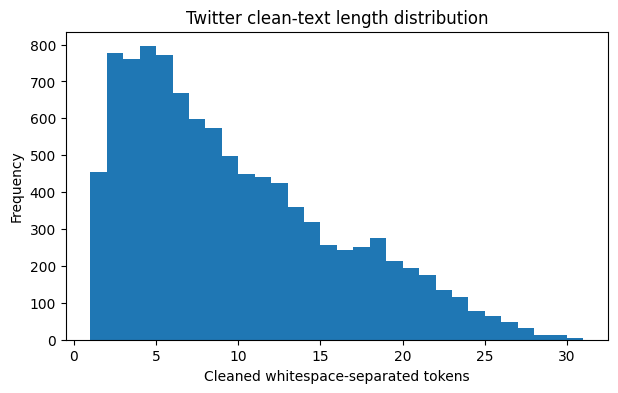

In [ ]:
# Load and inspect the supplied Twitter split.
twitter_df = pd.read_csv(
    "twitter_sentiment_fixed_split.csv"
)

print("Shape:", twitter_df.shape)
display(twitter_df.head(3))

print("\nSplit × label counts:")
display(
    pd.crosstab(
        twitter_df["split"],
        twitter_df["label"],
    )
)

print("\nMissing values:")
print(
    twitter_df[
        [
            "text",
            "clean_text",
            "label",
            "split",
        ]
    ].isna().sum()
)

twitter_df["clean_length"] = (
    twitter_df["clean_text"]
    .astype(str)
    .str.split()
    .str.len()
)

twitter_df["clean_length"].plot(
    kind="hist",
    bins=30,
    figsize=(7, 4),
    title="Twitter clean-text length distribution",
)

plt.xlabel(
    "Cleaned whitespace-separated tokens"
)
plt.show()

## Guided B2 — Prepare the Twitter splits, tokenizer and vocabulary

Use the **existing** `build_vocab()` helper. The only differences from IMDB are:

- use `clean_text` instead of the longer review text;
- use `TweetTokenizer` to handle tweets;
- create the vocabulary from **training tweets only**.

There is no need to rewrite the vocabulary-building function.

In [ ]:
# Use the supplied split exactly as stored.
twitter_train_df = (
    twitter_df[
        twitter_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

twitter_dev_df = (
    twitter_df[
        twitter_df["split"] == "dev"
    ]
    .reset_index(drop=True)
)

twitter_test_df = (
    twitter_df[
        twitter_df["split"] == "test"
    ]
    .reset_index(drop=True)
)

print("Train:", twitter_train_df.shape)
print("Dev:  ", twitter_dev_df.shape)
print("Test: ", twitter_test_df.shape)

tweet_tokenizer = TweetTokenizer(
    preserve_case=False,
    reduce_len=True,
)

word_pattern = re.compile(
    r"[a-z]+(?:'[a-z]+)?"
)

def tokenize_twitter_nn(text):
    tokens = tweet_tokenizer.tokenize(
        str(text)
    )

    return [
        token
        for token in tokens
        if word_pattern.fullmatch(token)
    ]

twitter_vocab, twitter_counter = build_vocab(
    twitter_train_df["clean_text"],
    tokenize_twitter_nn,
    max_vocab=10000,
    min_freq=2,
)

print(
    "Twitter vocabulary size:",
    len(twitter_vocab),
)
print(
    "20 most frequent training tokens:"
)
print(
    twitter_counter.most_common(20)
)

Train: (8000, 6)
Dev:   (1000, 6)
Test:  (1000, 6)
Twitter vocabulary size: 3858
20 most frequent training tokens:
[('i', 2595), ('to', 1754), ('you', 1738), ('the', 1590), ('a', 1290), ('and', 1134), ('my', 1057), ('for', 956), ('me', 844), ('it', 796), ('in', 751), ('is', 730), ('so', 687), ('of', 631), ('have', 593), ('this', 501), ('on', 492), ('but', 485), ('that', 484), ("i'm", 431)]


## Guided B3 — Convert tweets into tensors

Use the same `make_text_dataset()` helper from Part A, but specify `text_column="clean_text"` and `TWITTER_MAX_LEN = 40`.

You should obtain one ID vector of length 40 for each tweet. The training task below will use `make_loaders()` from Part A to create mini-batches.

In [ ]:
TWITTER_MAX_LEN = 40

# The same helper works with a different text column.
twitter_train_dataset = make_text_dataset(
    twitter_train_df,
    tokenize_twitter_nn,
    twitter_vocab,
    TWITTER_MAX_LEN,
    text_column="clean_text",
)

twitter_dev_dataset = make_text_dataset(
    twitter_dev_df,
    tokenize_twitter_nn,
    twitter_vocab,
    TWITTER_MAX_LEN,
    text_column="clean_text",
)

twitter_test_dataset = make_text_dataset(
    twitter_test_df,
    tokenize_twitter_nn,
    twitter_vocab,
    TWITTER_MAX_LEN,
    text_column="clean_text",
)

print("Training inputs:", twitter_train_dataset.tensors[0].shape)
print("Training labels:", twitter_train_dataset.tensors[1].shape)

Training inputs: torch.Size([8000, 40])
Training labels: torch.Size([8000])


## Task B1 — Train the Twitter MLP

Complete the four short steps in the code cell: **model → loss → optimiser → training**. The data has already been prepared, and the starting hyperparameters and DataLoaders are provided.

Use the IMDB model-training cell in **Part A, Section A7** as your example. Keep the supplied settings for the first run:

```text
embedding=32, hidden=32, dropout=0.3
batch=64, learning rate=0.001, weight decay=1e-5, epochs=10
```

**Important:** create a *new* model for Twitter and call `train_model()` so all configured epochs finish. The helper restores the checkpoint with the lowest development loss afterward.

In [ ]:
EMBEDDING_DIM = 32
HIDDEN_DIM = 32
DROPOUT = 0.3
BATCH_SIZE = 64
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-5
EPOCHS = 10

# Reuse the same DataLoader helper demonstrated in Part A.
twitter_train_loader, twitter_dev_loader, twitter_test_loader = make_loaders(
    twitter_train_dataset,
    twitter_dev_dataset,
    twitter_test_dataset,
    train_batch_size=BATCH_SIZE,
)

# Reset the seed before model construction so that
# repeated experiments are easier to compare.
set_seed()

twitter_model = MeanEmbeddingMLP(
    vocab_size=len(twitter_vocab),
    embedding_dim=EMBEDDING_DIM,
    hidden_dim=HIDDEN_DIM,
    dropout=DROPOUT,
).to(device)

twitter_loss_fn = nn.CrossEntropyLoss()

twitter_optimiser = torch.optim.Adam(
    twitter_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

twitter_history, twitter_best_dev_loss, twitter_best_dev_accuracy, twitter_best_epoch = train_model(
    twitter_model,
    twitter_train_loader,
    twitter_dev_loader,
    twitter_loss_fn,
    twitter_optimiser,
    device,
    epochs=EPOCHS,
)

Epoch 01 | train loss 0.6763 | dev loss 0.6623 | dev accuracy 0.631
Epoch 02 | train loss 0.6268 | dev loss 0.6280 | dev accuracy 0.664
Epoch 03 | train loss 0.5839 | dev loss 0.6058 | dev accuracy 0.681
Epoch 04 | train loss 0.5503 | dev loss 0.5901 | dev accuracy 0.688
Epoch 05 | train loss 0.5190 | dev loss 0.5775 | dev accuracy 0.713
Epoch 06 | train loss 0.4911 | dev loss 0.5680 | dev accuracy 0.722
Epoch 07 | train loss 0.4617 | dev loss 0.5616 | dev accuracy 0.721
Epoch 08 | train loss 0.4425 | dev loss 0.5508 | dev accuracy 0.738
Epoch 09 | train loss 0.4202 | dev loss 0.5467 | dev accuracy 0.736
Epoch 10 | train loss 0.4043 | dev loss 0.5438 | dev accuracy 0.740

Restored epoch 10 | best dev loss 0.5438 | dev accuracy 0.740


## Task B2 — Plot the learning curves

Make two simple plots using `twitter_history`:

1. **Training loss and development loss** versus epoch, together.
2. **Development accuracy** versus epoch, separately.

Use the already-completed plots in **Part A, Section A7** as a guide. Observe whether development loss follows training loss, and identify the epoch selected by the trainer.

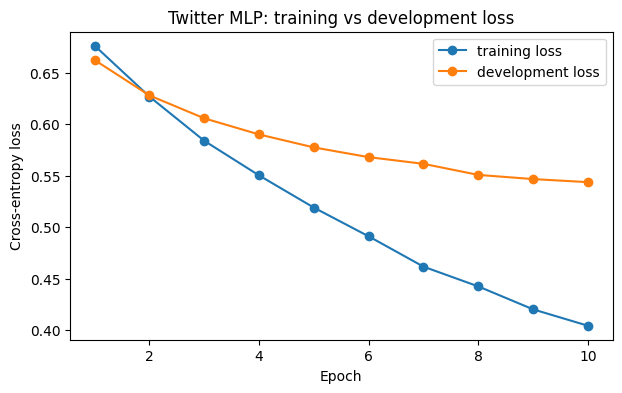

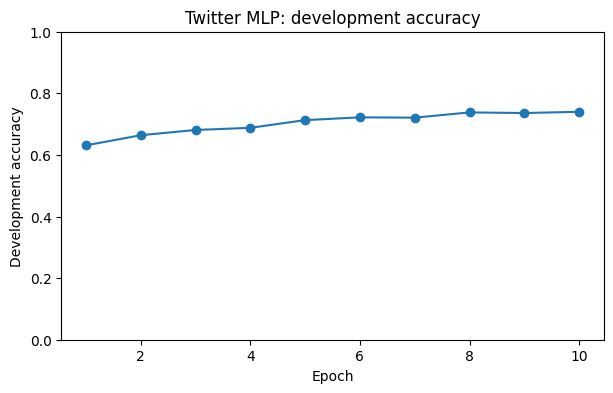

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    twitter_history["epoch"],
    twitter_history["train_loss"],
    marker="o",
    label="training loss",
)

ax.plot(
    twitter_history["epoch"],
    twitter_history["dev_loss"],
    marker="o",
    label="development loss",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title(
    "Twitter MLP: training vs development loss"
)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    twitter_history["epoch"],
    twitter_history["dev_accuracy"],
    marker="o",
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Development accuracy")
ax.set_ylim(0, 1)
ax.set_title(
    "Twitter MLP: development accuracy"
)
plt.show()

## Task B3 — Evaluate the Twitter test set

`evaluate_model()` has already been called for you below. Complete the remaining evaluation:

- calculate and print **macro F1** along with test loss and accuracy;
- plot a **confusion matrix** with the labels `negative` and `positive`.

Use the evaluation example in **Part A, Section A8**. Do not use test results to change the model or select a different checkpoint.

Test loss:     0.5441
Test accuracy: 0.735
Macro F1:      0.735


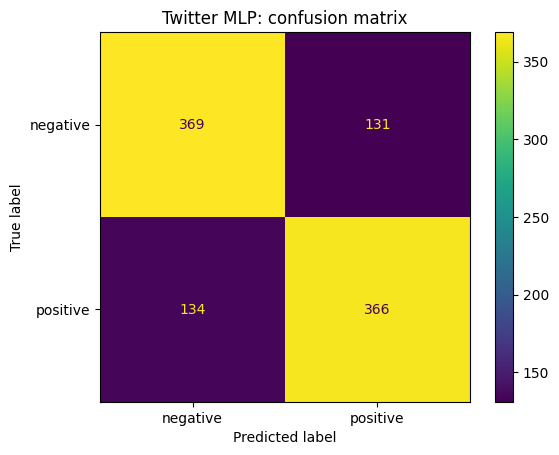

In [ ]:
twitter_test_loss, twitter_test_accuracy, twitter_test_predictions, twitter_test_targets = evaluate_model(
    twitter_model,
    twitter_test_loader,
    twitter_loss_fn,
    device,
)

twitter_test_f1 = f1_score(
    twitter_test_targets,
    twitter_test_predictions,
    average="macro",
)

print(
    f"Test loss:     {twitter_test_loss:.4f}"
)
print(
    f"Test accuracy: {twitter_test_accuracy:.3f}"
)
print(
    f"Macro F1:      {twitter_test_f1:.3f}"
)

twitter_cm = confusion_matrix(
    twitter_test_targets,
    twitter_test_predictions,
)

twitter_disp = ConfusionMatrixDisplay(
    confusion_matrix=twitter_cm,
    display_labels=[
        "negative",
        "positive",
    ],
)

twitter_disp.plot()
plt.title(
    "Twitter MLP: confusion matrix"
)
plt.show()

## Task B4 — Look at a few incorrect predictions

The prepared `twitter_results` DataFrame contains the original test tweets. Add `predicted_label` using `ID_TO_LABEL`, filter the mistakes and display the first eight with:

```text
text | clean_text | label | predicted_label
```

Use the IMDB example from **Part A, Section A9** as a guide. Find one example where the cleaned wording could be ambiguous.

In [ ]:
twitter_results = (
    twitter_test_df
    .reset_index(drop=True)
    .copy()
)

twitter_results["predicted_label"] = [
    ID_TO_LABEL[prediction]
    for prediction
    in twitter_test_predictions
]

twitter_errors = twitter_results[
    twitter_results["label"]
    != twitter_results["predicted_label"]
].copy()

display(
    twitter_errors[
        [
            "text",
            "clean_text",
            "label",
            "predicted_label",
        ]
    ].head(8)
)

,text,clean_text,label,predicted_label
3,@yslzaint this one :( http://t.co/s5Dw4o9nvb,this one,negative,positive
19,Dem free tix to Big Bang concert :(,dem free tix to big bang concert,negative,positive
26,Identity crisis :(,identity crisis,negative,positive
29,So Im going to sleep Goodnight :),so im going to sleep goodnight,positive,negative
39,@TheLinderman_ you're probably right... :(,you're probably right,negative,positive
41,"@KumonePina_bot Just for that, you won't get a...",just for that you won't get a cupcake,negative,positive
52,@swgzl do you not like ballads :-( i think it ...,do you not like ballads i think it emphasis th...,negative,positive
55,Lucky me! ~ Thanks sa spag and cake!! :)) &lt;3,lucky me thanks sa spag and cake,positive,negative


## Guided demonstration — Why word order still matters

Run the provided demonstration comparing `good day bad` and `bad day good`.

Both sequences contain the same tokens in a different order. **Mean pooling produces (approximately) the same representation**, so the model cannot recognise word order from these pooled vectors alone. This limitation motivates sequence models and attention-based models introduced later.

In [ ]:
order_a = [
    "good",
    "day",
    "bad",
]

order_b = [
    "bad",
    "day",
    "good",
]

ids_a = torch.tensor(
    [encode_text(" ".join(order_a), tokenize_twitter_nn, twitter_vocab, 8)],
    dtype=torch.long,
).to(device)

ids_b = torch.tensor(
    [encode_text(" ".join(order_b), tokenize_twitter_nn, twitter_vocab, 8)],
    dtype=torch.long,
).to(device)

twitter_model.eval()

with torch.no_grad():
    twitter_vector_a = (
        twitter_model.mean_pool(ids_a)
    )

    twitter_vector_b = (
        twitter_model.mean_pool(ids_b)
    )

    twitter_probability_a = torch.softmax(
        twitter_model(ids_a),
        dim=1,
    )[0, 1].item()

    twitter_probability_b = torch.softmax(
        twitter_model(ids_b),
        dim=1,
    )[0, 1].item()

print(
    "Maximum absolute vector difference:",
    (
        twitter_vector_a
        - twitter_vector_b
    ).abs().max().item(),
)

print(
    "P(positive) for A:",
    round(
        twitter_probability_a,
        6,
    ),
)

print(
    "P(positive) for B:",
    round(
        twitter_probability_b,
        6,
    ),
)

Maximum absolute vector difference: 5.960464477539063e-08
P(positive) for A: 0.734427
P(positive) for B: 0.734427


# Wrap-up

You have completed the same neural sentiment-classification workflow for **IMDB** and **Twitter**:

```text
text → tokens → vocabulary IDs → padding → DataLoader
→ trainable embeddings → masked mean pooling → hidden layer
→ two logits → cross-entropy → backpropagation → Adam
→ development-loss checkpoint → final test metrics
```

**Main ideas:**

- build vocabularies using **training data only**;
- use the **development split** for model selection, not the test split;
- complete all configured training epochs and then restore the best completed checkpoint;
- pass **raw logits** and integer class labels to `CrossEntropyLoss`;
- use learning curves, macro F1, confusion matrices and example mistakes to understand a model;
- mean pooling is simple but ignores token order.

Save your notebook after completing Tasks B1–B4.